Import Libraries


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, classification_report

Import Dataset

In [ ]:
df = pd.read_csv("/content/medical_students_dataset.csv")
df_copy = df.copy()
df.columns

Index(['Student ID', 'Age', 'Gender', 'Height', 'Weight', 'Blood Type', 'BMI',
       'Temperature', 'Heart Rate', 'Blood Pressure', 'Cholesterol',
       'Diabetes', 'Smoking'],
      dtype='object')

In [ ]:
df.head(5)

,Student ID,Age,Gender,Height,Weight,Blood Type,BMI,Temperature,Heart Rate,Blood Pressure,Cholesterol,Diabetes,Smoking
0,1.0,18.0,Female,161.777924,72.354947,O,27.645835,NaN,95.0,109.0,203.0,No,NaN
1,2.0,NaN,Male,152.069157,47.630941,B,NaN,98.714977,93.0,104.0,163.0,No,No
2,3.0,32.0,Female,182.537664,55.741083,A,16.729017,98.260293,76.0,130.0,216.0,Yes,No
3,NaN,30.0,Male,182.112867,63.332207,B,19.096042,98.839605,99.0,112.0,141.0,No,Yes
4,5.0,23.0,Female,NaN,46.234173,O,NaN,98.480008,95.0,NaN,231.0,No,No


EDA & Data Pre-processing

In [ ]:
# Handling missing values :
df.fillna(df.median(numeric_only=True), inplace=True)
df.fillna(df.mode().iloc[0], inplace=True)
df.describe()

,Student ID,Age,Height,Weight,BMI,Temperature,Heart Rate,Blood Pressure,Cholesterol
count,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.00000,200000.000000
mean,49970.987870,26.019405,174.942384,69.972365,23.272123,98.600818,79.553390,114.60223,184.437725
std,27397.627615,4.639565,13.706162,16.433632,6.675617,0.474845,10.949531,13.66486,35.632528
min,1.000000,18.000000,150.000041,40.000578,10.074837,96.397835,60.000000,90.00000,120.000000
25%,27730.000000,22.000000,163.859439,56.626643,18.382809,98.306875,71.000000,104.00000,156.000000
50%,49943.500000,26.000000,174.899914,69.979384,22.671401,98.599654,80.000000,115.00000,184.000000
75%,72214.000000,30.000000,186.079360,83.316641,27.255521,98.897102,88.000000,126.00000,213.000000
max,100000.000000,34.000000,199.998639,99.999907,44.355113,100.824857,99.000000,139.00000,249.000000


In [ ]:
print ('Shape of the dataset is {}. This dataset contains {} rows and {} columns.'.format(df.shape,df.shape[0],df.shape[1]))

Shape of the dataset is (200000, 13). This dataset contains 200000 rows and 13 columns.


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 13 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   Student ID      200000 non-null  float64
 1   Age             200000 non-null  float64
 2   Gender          200000 non-null  object 
 3   Height          200000 non-null  float64
 4   Weight          200000 non-null  float64
 5   Blood Type      200000 non-null  object 
 6   BMI             200000 non-null  float64
 7   Temperature     200000 non-null  float64
 8   Heart Rate      200000 non-null  float64
 9   Blood Pressure  200000 non-null  float64
 10  Cholesterol     200000 non-null  float64
 11  Diabetes        200000 non-null  object 
 12  Smoking         200000 non-null  object 
dtypes: float64(9), object(4)
memory usage: 19.8+ MB


Data Spliting

In [ ]:
#numerical features
numerical_data = df.select_dtypes(include='number')
numerical_features=numerical_data.columns.tolist()
print(f'There are {len(numerical_features)} numerical features:', '\n')
print(numerical_features)

There are 9 numerical features: 

['Student ID', 'Age', 'Height', 'Weight', 'BMI', 'Temperature', 'Heart Rate', 'Blood Pressure', 'Cholesterol']


In [ ]:
#categoricalfeatures
categorical_data = df.select_dtypes(include= 'object')
categorical_features = categorical_data.columns.tolist()
print(f'There are {len(categorical_features)} categorical features:', '\n')
print(categorical_features)

There are 4 categorical features: 

['Gender', 'Blood Type', 'Diabetes', 'Smoking']


Descriptive Analysis

In [ ]:
#Summary Statistics
#For numerical features
numerical_data.describe().T

,count,mean,std,min,25%,50%,75%,max
Student ID,200000.0,49970.987870,27397.627615,1.000000,27730.000000,49943.500000,72214.000000,100000.000000
Age,200000.0,26.019405,4.639565,18.000000,22.000000,26.000000,30.000000,34.000000
Height,200000.0,174.942384,13.706162,150.000041,163.859439,174.899914,186.079360,199.998639
Weight,200000.0,69.972365,16.433632,40.000578,56.626643,69.979384,83.316641,99.999907
BMI,200000.0,23.272123,6.675617,10.074837,18.382809,22.671401,27.255521,44.355113
Temperature,200000.0,98.600818,0.474845,96.397835,98.306875,98.599654,98.897102,100.824857
Heart Rate,200000.0,79.553390,10.949531,60.000000,71.000000,80.000000,88.000000,99.000000
Blood Pressure,200000.0,114.602230,13.664860,90.000000,104.000000,115.000000,126.000000,139.000000
Cholesterol,200000.0,184.437725,35.632528,120.000000,156.000000,184.000000,213.000000,249.000000


In [ ]:
# For categorical features
categorical_data.describe().T

,count,unique,top,freq
Gender,200000,2,Male,110005
Blood Type,200000,4,B,65537
Diabetes,200000,2,No,181986
Smoking,200000,2,No,163971


In [ ]:
#Variance of each numerical features
numerical_data.var()

,0
Student ID,7.506300e+08
Age,2.152557e+01
Height,1.878589e+02
Weight,2.700643e+02
BMI,4.456386e+01
Temperature,2.254774e-01
Heart Rate,1.198922e+02
Blood Pressure,1.867284e+02
Cholesterol,1.269677e+03


In [ ]:
numerical_data.skew()

,0
Student ID,0.001476
Age,-0.002154
Height,0.003429
Weight,0.004938
BMI,0.491336
Temperature,0.011851
Heart Rate,-0.014707
Blood Pressure,-0.014790
Cholesterol,0.008474


In [ ]:
numerical_data.nunique()

,0
Student ID,98977
Age,17
Height,98981
Weight,99025
BMI,98984
Temperature,98971
Heart Rate,40
Blood Pressure,50
Cholesterol,130


In [ ]:
#Data Quality
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nDuplicate entries:", df.duplicated().sum())


Missing values per column:
Student ID        0
Age               0
Gender            0
Height            0
Weight            0
Blood Type        0
BMI               0
Temperature       0
Heart Rate        0
Blood Pressure    0
Cholesterol       0
Diabetes          0
Smoking           0
dtype: int64

Duplicate entries: 12879


Categorical Features

In [ ]:
#Number of unique values in each categorical feature
unique_counts = categorical_data.nunique()
print(unique_counts)

Gender        2
Blood Type    4
Diabetes      2
Smoking       2
dtype: int64


Histogram

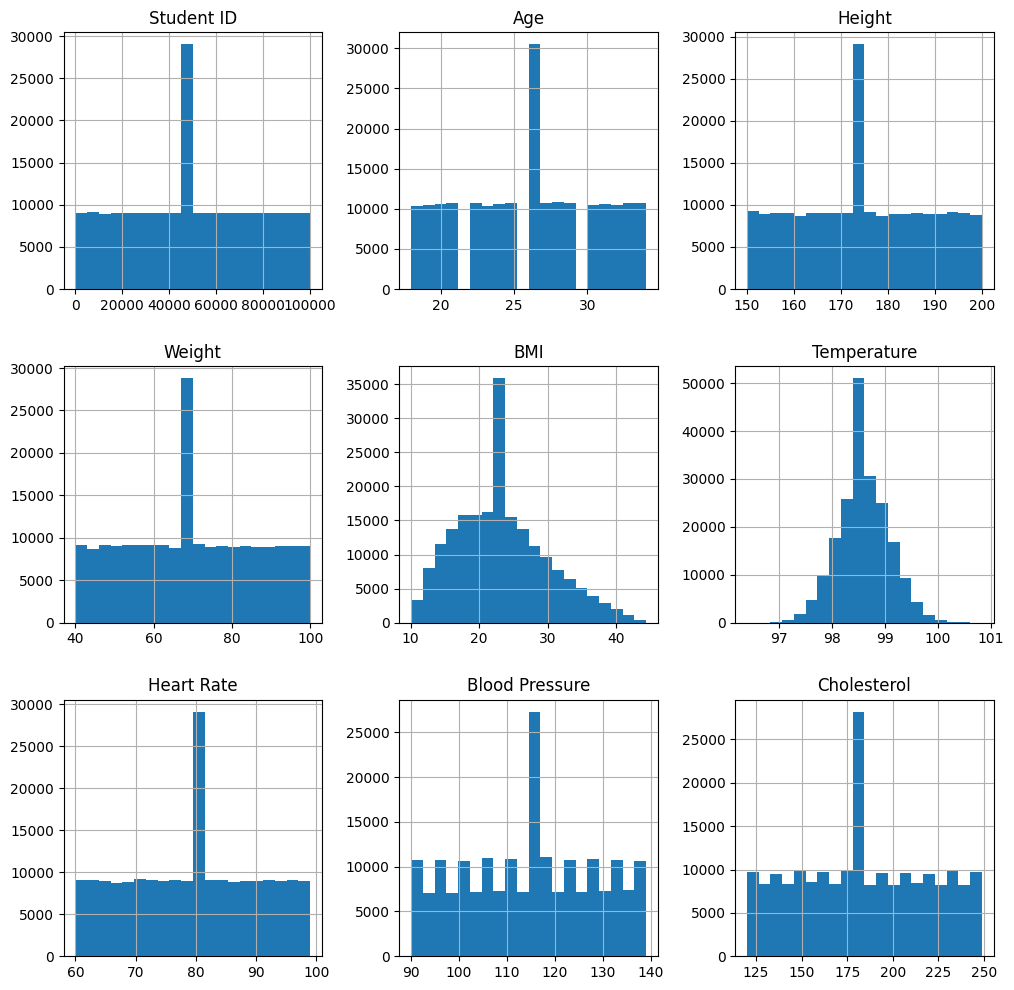

In [ ]:
df.hist(bins=20, figsize=(12, 12))
plt.show()

Box-Plot

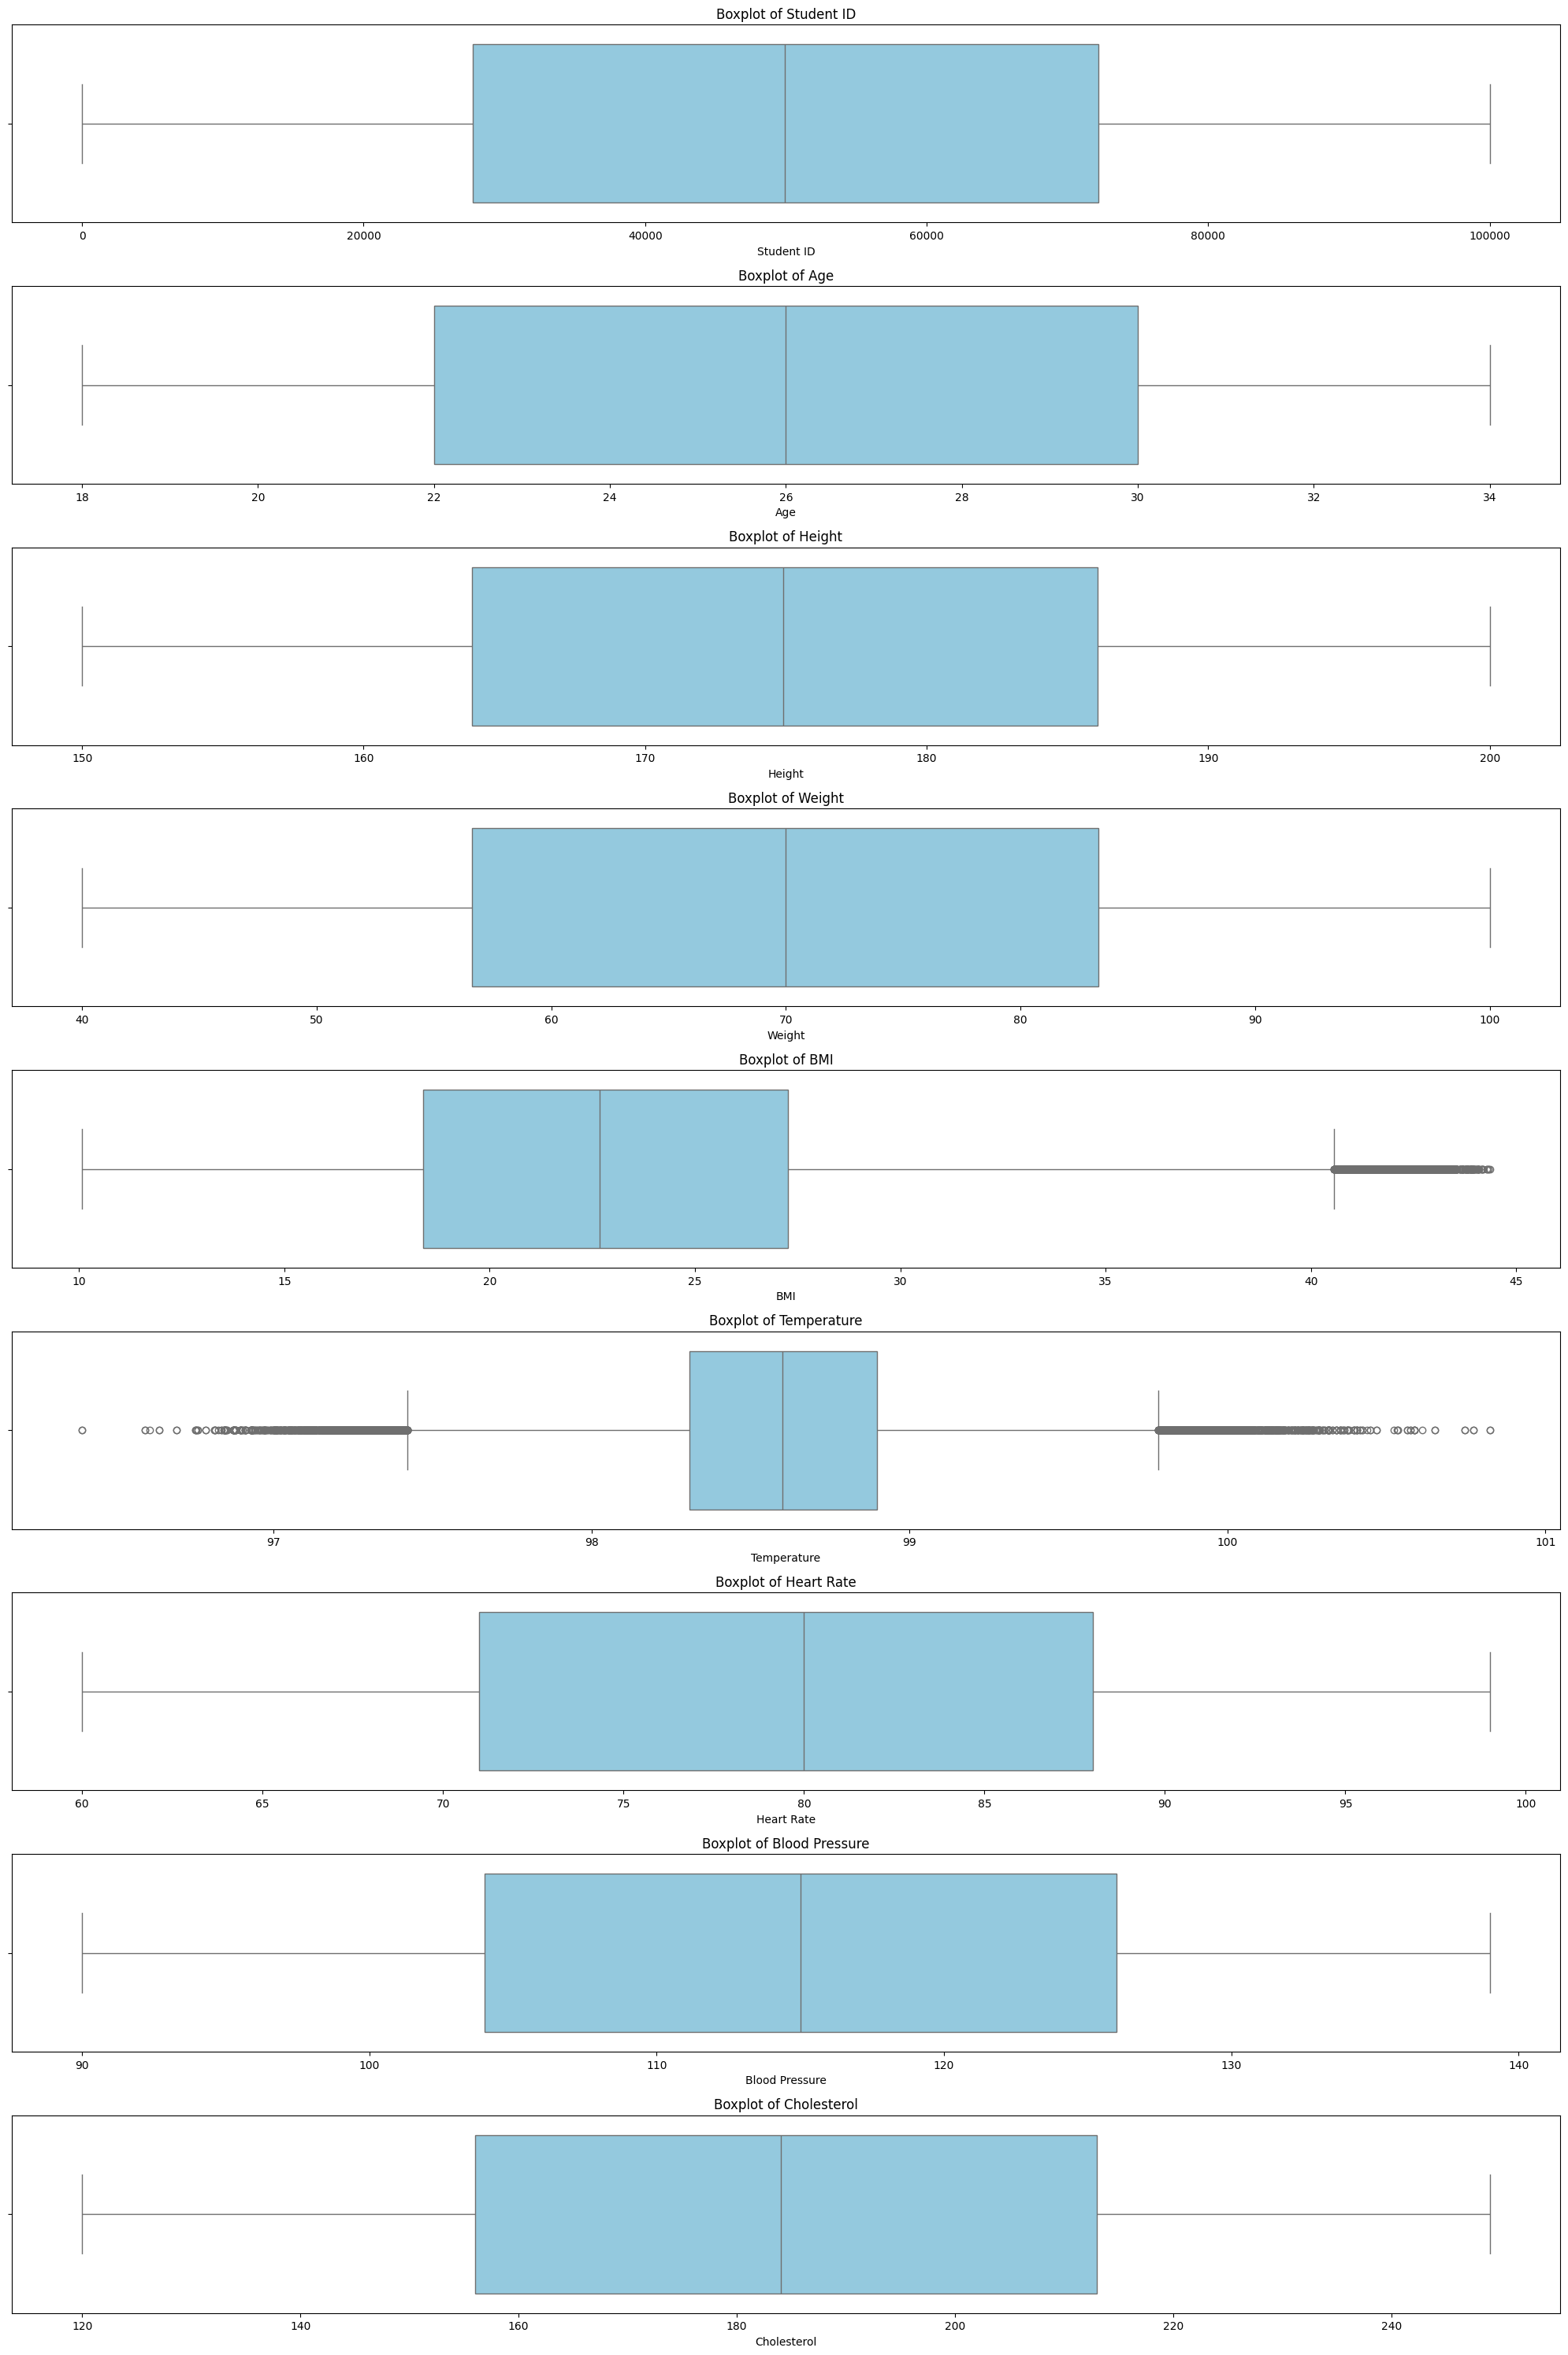

In [ ]:
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
plt.figure(figsize=(20, 30))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(len(numeric_cols), 1, i)
    sns.boxplot(x = df[col], color='skyblue')
    plt.title(f'Boxplot of {col}', fontsize=12)
    plt.tight_layout()
plt.show()

Correlation Analysis

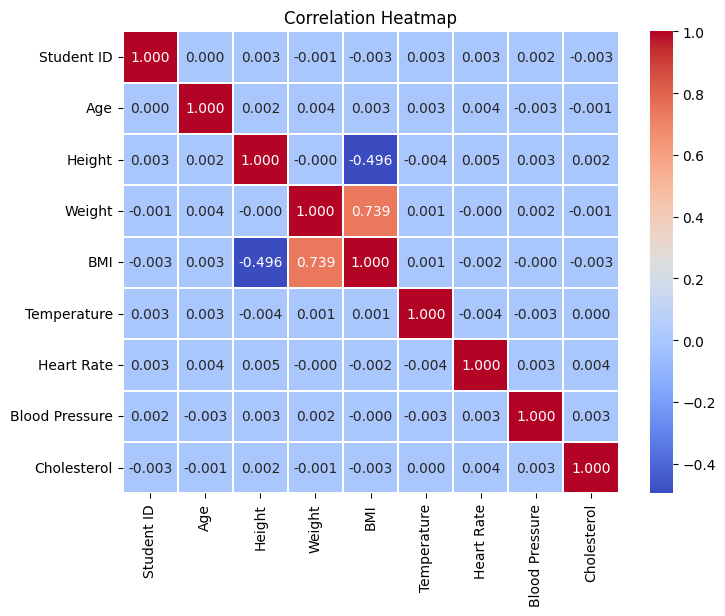

In [ ]:
correlation_matrix = numerical_data.corr()
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.3f', linewidths=0.3)
plt.title('Correlation Heatmap')
plt.show()

Checking Imbalance in Data

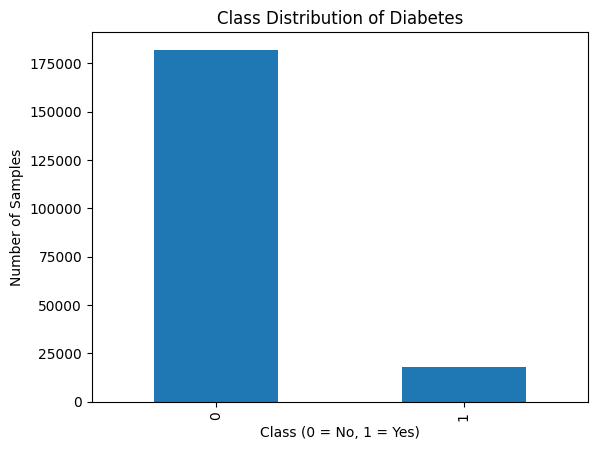

In [ ]:
L = LabelEncoder()
df['Diabetes_encoded'] = L.fit_transform(df['Diabetes'])

df['Diabetes_encoded'].value_counts().plot(kind='bar')
plt.title("Class Distribution of Diabetes")
plt.xlabel("Class (0 = No, 1 = Yes)")
plt.ylabel("Number of Samples")
plt.show()

Pre Processing

In [ ]:
target = 'Diabetes'
print("\nDiabetes class distribution:\n", df[target].value_counts(normalize=True))
# Features types
categorical_cols = ['Gender', 'Blood Type', 'Smoking']
numerical_cols = ['Age', 'Height', 'Weight', 'BMI', 'Temperature',
                  'Heart Rate', 'Blood Pressure', 'Cholesterol']

print("\nCategorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)

# Features and target
X = df.drop(columns=[target])
y = df[target].map({'Yes': 1, 'No': 0})



Diabetes class distribution:
 Diabetes
No     0.90993
Yes    0.09007
Name: proportion, dtype: float64

Categorical columns: ['Gender', 'Blood Type', 'Smoking']
Numerical columns: ['Age', 'Height', 'Weight', 'BMI', 'Temperature', 'Heart Rate', 'Blood Pressure', 'Cholesterol']


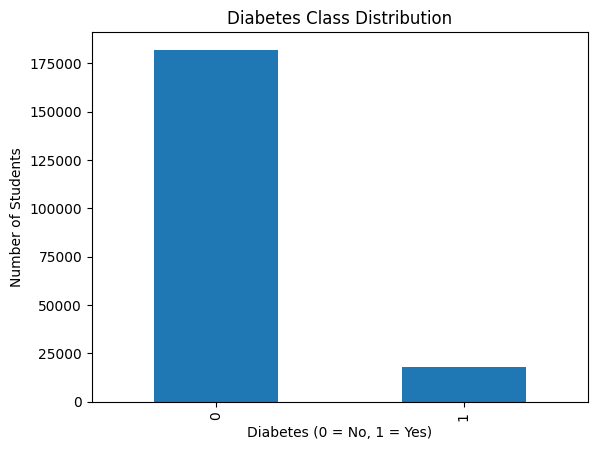

In [ ]:
#Data Pre-processing (DIABETES)
df.columns = df.columns.str.strip().str.replace(' ', '_')

#Numerical columns
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())

#Categorical columns
cat_cols = ['Diabetes', 'Gender', 'Smoking']
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

#Diabetes: No → 0, Yes → 1
df['Diabetes'] = (
    df['Diabetes']
    .astype(str)
    .str.strip()
    .str.lower()
    .map({'no': 0, 'yes': 1})
)

#Gender: Female → 0, Male → 1
df['Gender'] = (
    df['Gender']
    .astype(str)
    .str.strip()
    .str.lower()
    .map({'female': 0, 'male': 1})
)

#Smoking: No → 0, Yes → 1
df['Smoking'] = (
    df['Smoking']
    .astype(str)
    .str.strip()
    .str.lower()
    .map({'no': 0, 'yes': 1})
)

df = df.dropna(subset=['Diabetes', 'Gender', 'Smoking'])

df[['Diabetes', 'Gender', 'Smoking']] = df[['Diabetes', 'Gender', 'Smoking']].astype(int)

X = df[['Age', 'Gender', 'BMI', 'Blood_Pressure', 'Cholesterol', 'Smoking']]
y = df['Diabetes']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

y.value_counts().plot(kind='bar')
plt.xlabel('Diabetes (0 = No, 1 = Yes)')
plt.ylabel('Number of Students')
plt.title('Diabetes Class Distribution')
plt.show()

Train Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, stratify=y, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

KNN

In [ ]:
knn = KNeighborsClassifier()
knn.fit(X_train_scaled, y_train)
y_pred_knn = knn.predict(X_test_scaled)
print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))
print("KNN Confusion Matrix:\n", confusion_matrix(y_test, y_pred_knn))
print("KNN Classification Report:\n", classification_report(y_test, y_pred_knn))

KNN Accuracy: 0.902125
KNN Confusion Matrix:
 [[35958   439]
 [ 3476   127]]
KNN Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.99      0.95     36397
           1       0.22      0.04      0.06      3603

    accuracy                           0.90     40000
   macro avg       0.57      0.51      0.50     40000
weighted avg       0.85      0.90      0.87     40000



Decision Tree


In [ ]:
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train_scaled, y_train)
y_pred_dt = dt.predict(X_test_scaled)
print("Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Decision Tree Confusion Matrix:\n", confusion_matrix(y_test, y_pred_dt))

Decision Tree Accuracy: 0.8892
Decision Tree Confusion Matrix:
 [[34044  2353]
 [ 2079  1524]]


Logistic Regression


In [ ]:
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)
print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Logistic Regression Confusion Matrix:\n", confusion_matrix(y_test, y_pred_lr))

Logistic Regression Accuracy: 0.909925
Logistic Regression Confusion Matrix:
 [[36397     0]
 [ 3603     0]]


Linear Regression

In [ ]:
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)
y_pred = lr_model.predict(X_test_scaled)
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
print("Linear Regression Results:")
print("R² Score:", r2)
print("Mean Squared Error:", mse)

Linear Regression Results:
R² Score: -4.58100713964793e-05
Mean Squared Error: 0.08196524903690906


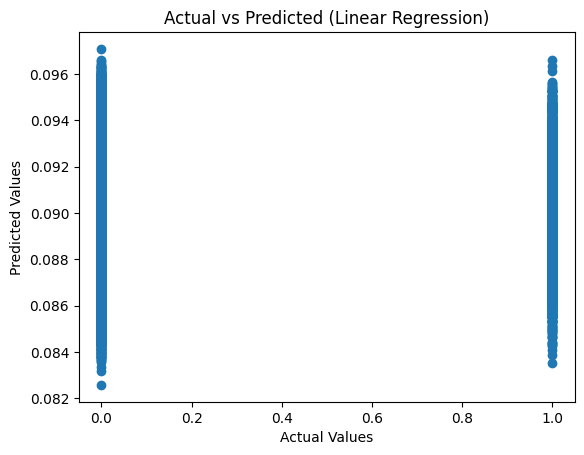

In [ ]:
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted (Linear Regression)")
plt.show()

Naive Bayes

In [ ]:
nb = GaussianNB()
nb.fit(X_train_scaled, y_train)
y_pred_nb = nb.predict(X_test_scaled)
print("Naive Bayes Accuracy:", accuracy_score(y_test, y_pred_nb))
print("Naive Bayes Confusion Matrix:\n", confusion_matrix(y_test, y_pred_nb))

Naive Bayes Accuracy: 0.909925
Naive Bayes Confusion Matrix:
 [[36397     0]
 [ 3603     0]]


Neural Network

In [ ]:
mlp = MLPClassifier(hidden_layer_sizes=(50,50), max_iter=500, random_state=42)
mlp.fit(X_train_scaled, y_train)
y_pred_mlp = mlp.predict(X_test_scaled)
print("Neural Network Accuracy:", accuracy_score(y_test, y_pred_mlp))
print("Neural Network Confusion Matrix:\n", confusion_matrix(y_test, y_pred_mlp))

Neural Network Accuracy: 0.909925
Neural Network Confusion Matrix:
 [[36397     0]
 [ 3603     0]]


ROC & AUC


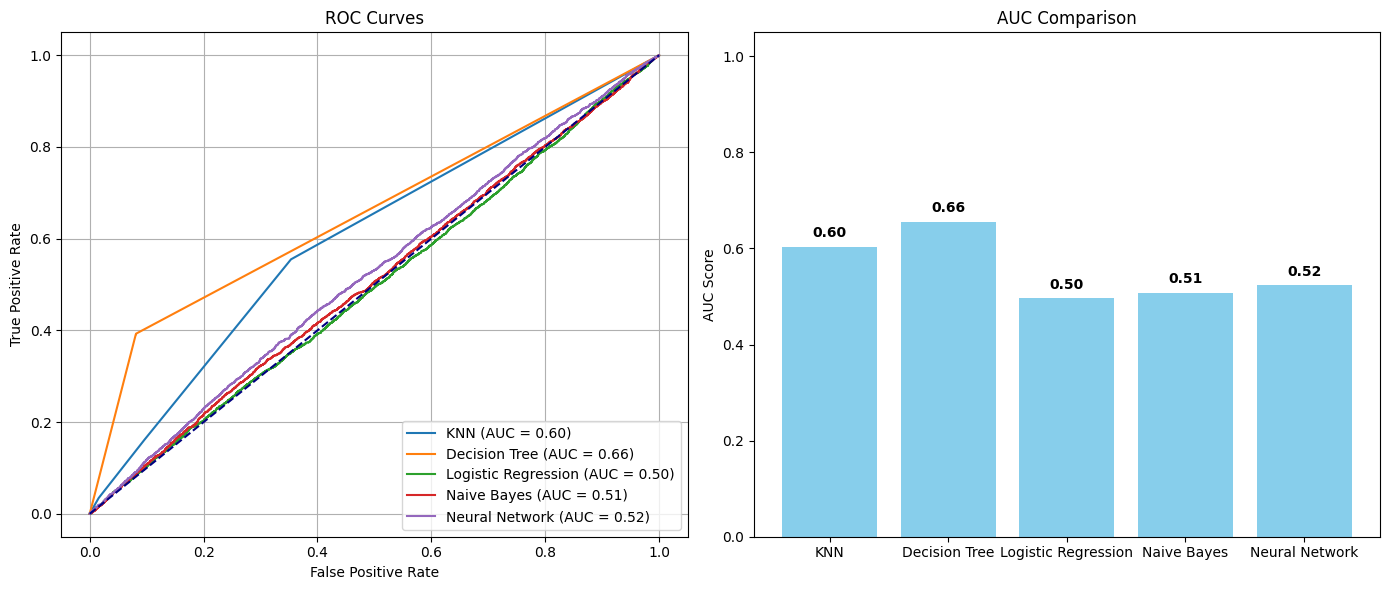

In [ ]:
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.preprocessing import label_binarize

y_test_bin = label_binarize(y_test, classes=[0, 1]).ravel()

#Defining models
models = {
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Naive Bayes": GaussianNB(),
    "Neural Network": MLPClassifier(max_iter=1000)
}

auc_scores = {}

#figure for ROC curves
plt.figure(figsize=(14, 6))

#ROC Curves
plt.subplot(1, 2, 1)
for name, model in models.items():
    model.fit(X_train, y_train)

    #Prediction probabilities
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)

    #ROC
    fpr, tpr, _ = roc_curve(y_test_bin, y_score)
    roc_auc = auc(fpr, tpr)
    auc_scores[name] = roc_auc

    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
plt.legend(loc='lower right')
plt.grid(True)

#AUC Bar Chart
plt.subplot(1, 2, 2)
plt.bar(auc_scores.keys(), auc_scores.values(), color='skyblue')
plt.ylim(0, 1.05)
plt.ylabel('AUC Score')
plt.title('AUC Comparison')
for i, v in enumerate(auc_scores.values()):
    plt.text(i, v + 0.02, f"{v:.2f}", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

The ROC curves show how well each model distinguishes between the two classes at different thresholds. Curves closer to the top-left corner indicate better performance. The AUC values summarize this performance as a single number between 0 and 1 — higher AUC means better classification. Comparing the AUC bar chart, we can quickly see which model performs best overall.




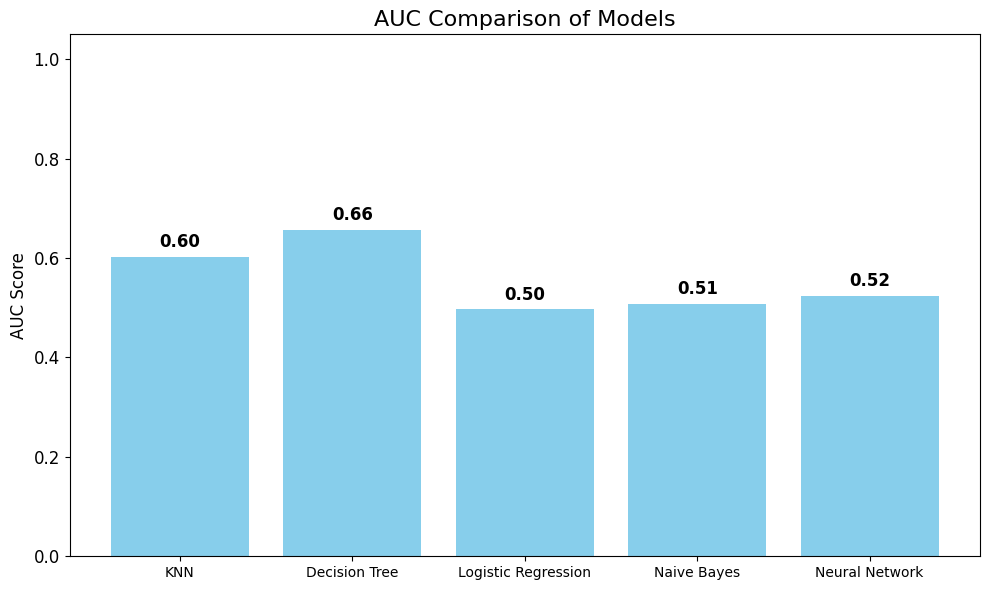

In [ ]:
plt.figure(figsize=(10, 6))

bars = plt.bar(auc_scores.keys(), auc_scores.values(), color='skyblue')

plt.ylim(0, 1.05)
plt.ylabel('AUC Score', fontsize=12)
plt.title('AUC Comparison of Models', fontsize=16)
plt.xticks(rotation=0, fontsize=10)
plt.yticks(fontsize=12)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.02, f'{height:.2f}',
             ha='center', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

##Confusion Matrix


Logistic Regression


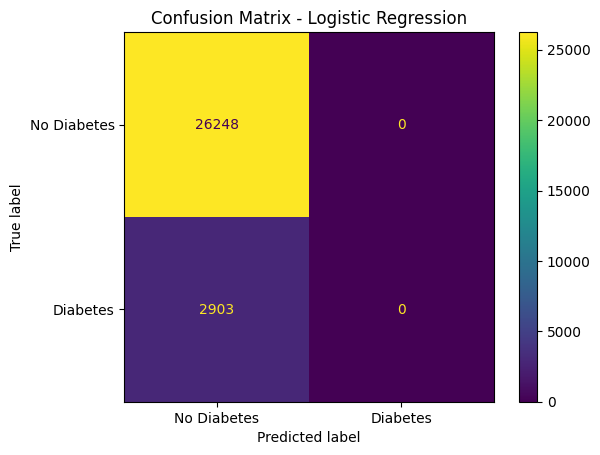

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

cm_lr = confusion_matrix(y_test, y_pred_lr)

disp_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr,
                                 display_labels=['No Diabetes', 'Diabetes'])

disp_lr.plot()
plt.title('Confusion Matrix - Logistic Regression')
plt.show()


KNN

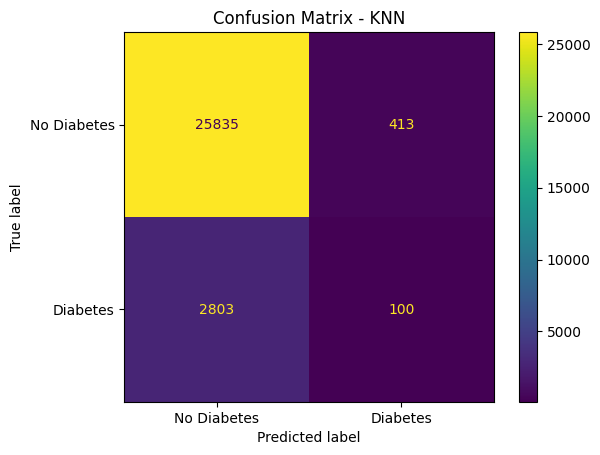

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_test)

cm_knn = confusion_matrix(y_test, y_pred_knn)

disp_knn = ConfusionMatrixDisplay(confusion_matrix=cm_knn,
                                  display_labels=['No Diabetes', 'Diabetes'])

disp_knn.plot()
plt.title('Confusion Matrix - KNN')
plt.show()


Decision Tree

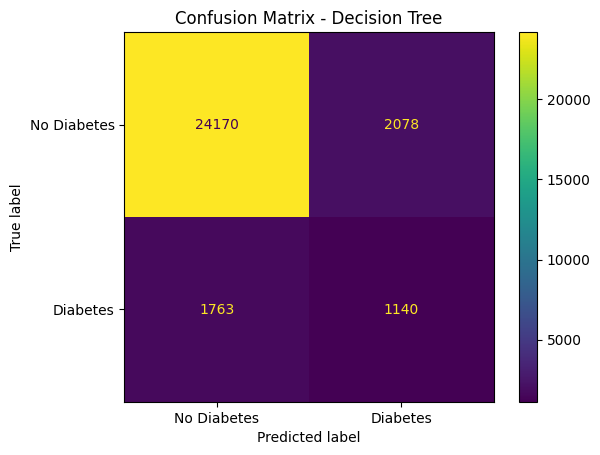

In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)

cm_dt = confusion_matrix(y_test, y_pred_dt)

disp_dt = ConfusionMatrixDisplay(confusion_matrix=cm_dt,
                                 display_labels=['No Diabetes', 'Diabetes'])

disp_dt.plot()
plt.title('Confusion Matrix - Decision Tree')
plt.show()


NB

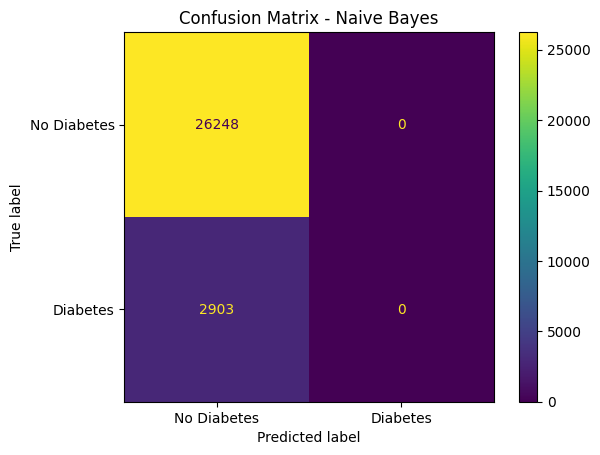

In [ ]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(X_train, y_train)

y_pred_nb = nb.predict(X_test)

cm_nb = confusion_matrix(y_test, y_pred_nb)

disp_nb = ConfusionMatrixDisplay(confusion_matrix=cm_nb,
                                 display_labels=['No Diabetes', 'Diabetes'])

disp_nb.plot()
plt.title('Confusion Matrix - Naive Bayes')
plt.show()


Neural Network

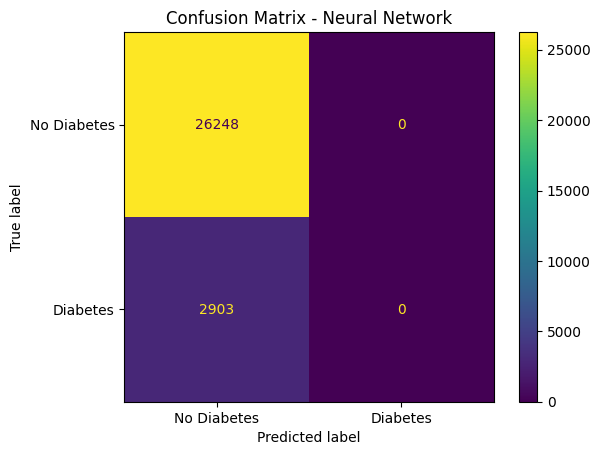

In [ ]:
from sklearn.neural_network import MLPClassifier

nn = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, random_state=42)
nn.fit(X_train, y_train)

y_pred_nn = nn.predict(X_test)

cm_nn = confusion_matrix(y_test, y_pred_nn)

disp_nn = ConfusionMatrixDisplay(confusion_matrix=cm_nn,
                                 display_labels=['No Diabetes', 'Diabetes'])

disp_nn.plot()
plt.title('Confusion Matrix - Neural Network')
plt.show()


In [ ]:
from sklearn.metrics import accuracy_score

# Accuracy calculation
accuracy_knn = accuracy_score(y_test, y_pred_knn)
accuracy_lr  = accuracy_score(y_test, y_pred_lr)
accuracy_dt  = accuracy_score(y_test, y_pred_dt)
accuracy_nb  = accuracy_score(y_test, y_pred_nb)
accuracy_nn  = accuracy_score(y_test, y_pred_nn)

print("KNN Accuracy:", accuracy_knn)
print("Logistic Regression Accuracy:", accuracy_lr)
print("Decision Tree Accuracy:", accuracy_dt)
print("Naive Bayes Accuracy:", accuracy_nb)
print("Neural Network Accuracy:", accuracy_nn)

import matplotlib.pyplot as plt

models = [
    'KNN',
    'Logistic Regression',
    'Decision Tree',
    'Naive Bayes',
    'Neural Network'
]

accuracies = [
    accuracy_knn,
    accuracy_lr,
    accuracy_dt,
    accuracy_nb,
    accuracy_nn
]

plt.figure(figsize=(8, 6))
plt.bar(models, accuracies)
plt.xlabel('Models')
plt.ylabel('Accuracy')
plt.title('Model Accuracy Comparison')
plt.ylim(0, 1)
plt.show()